In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

VARIANT = 'occupancy'   
#шлях до даних
DATA = Path('data')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)

if VARIANT == 'bean':
    df = pd.read_csv(DATA / 'drybean.csv')
    target = 'Class'
    features = [c for c in df.columns if c not in ('Class', 'split')]
else:
    df = pd.read_csv(DATA / 'occupancy.csv')
    target = 'Occupancy'
    features = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

#дані вже розмічені
train, val, test = (df[df['split'] == s] for s in ('train', 'val', 'test'))
X_tr, y_tr = train[features], train[target]
X_va, y_va = val[features], val[target]
X_te, y_te = test[features], test[target]
print('train / validation / test:', len(train), len(val), len(test))

train / validation / test: 8143 2665 9752


## Завдання 1. Знайомство з даними

                  date  Temperature  Humidity  Light     CO2  HumidityRatio  Occupancy  split
0  2015-02-04 17:51:00        23.18   27.2720  426.0  721.25       0.004793          1  train
1  2015-02-04 17:51:59        23.15   27.2675  429.5  714.00       0.004783          1  train
2  2015-02-04 17:53:00        23.15   27.2450  426.0  713.50       0.004779          1  train
3  2015-02-04 17:54:00        23.15   27.2000  426.0  708.25       0.004772          1  train
4  2015-02-04 17:55:00        23.10   27.2000  426.0  704.50       0.004757          1  train
        Temperature      Humidity         Light           CO2  HumidityRatio     Occupancy
count  20560.000000  20560.000000  20560.000000  20560.000000   20560.000000  20560.000000
mean      20.906212     27.655925    130.756622    690.553276       0.004228      0.231031
std        1.055315      4.982154    210.430875    311.201281       0.000768      0.421503
min       19.000000     16.745000      0.000000    412.750000       0.00

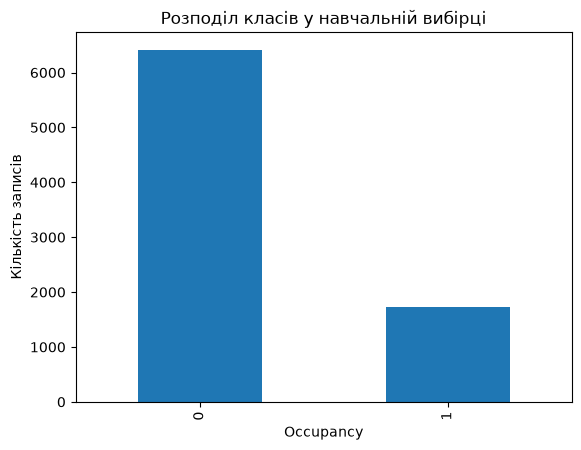

Найчастіший клас: 0
Baseline accuracy: 0.6352720450281426


In [ ]:
#(а)
print(df.head())
print(df.describe())

#(б)
class_counts = y_tr.value_counts()
print(class_counts)

class_counts.plot(kind='bar')
plt.title('Розподіл класів у навчальній вибірці')
plt.xlabel('Occupancy')
plt.ylabel('Кількість записів')
plt.show()

#(в)
most_frequent_class = y_tr.value_counts().idxmax()
y_va_baseline = np.full(len(y_va), most_frequent_class)
baseline_accuracy = accuracy_score(y_va, y_va_baseline)
print('Найчастіший клас:', most_frequent_class)
print('Baseline accuracy:', baseline_accuracy)

## Завдання 2. Дерево рішень

Train accuracy: 0.9893159769126857
Validation accuracy: 0.9782363977485928


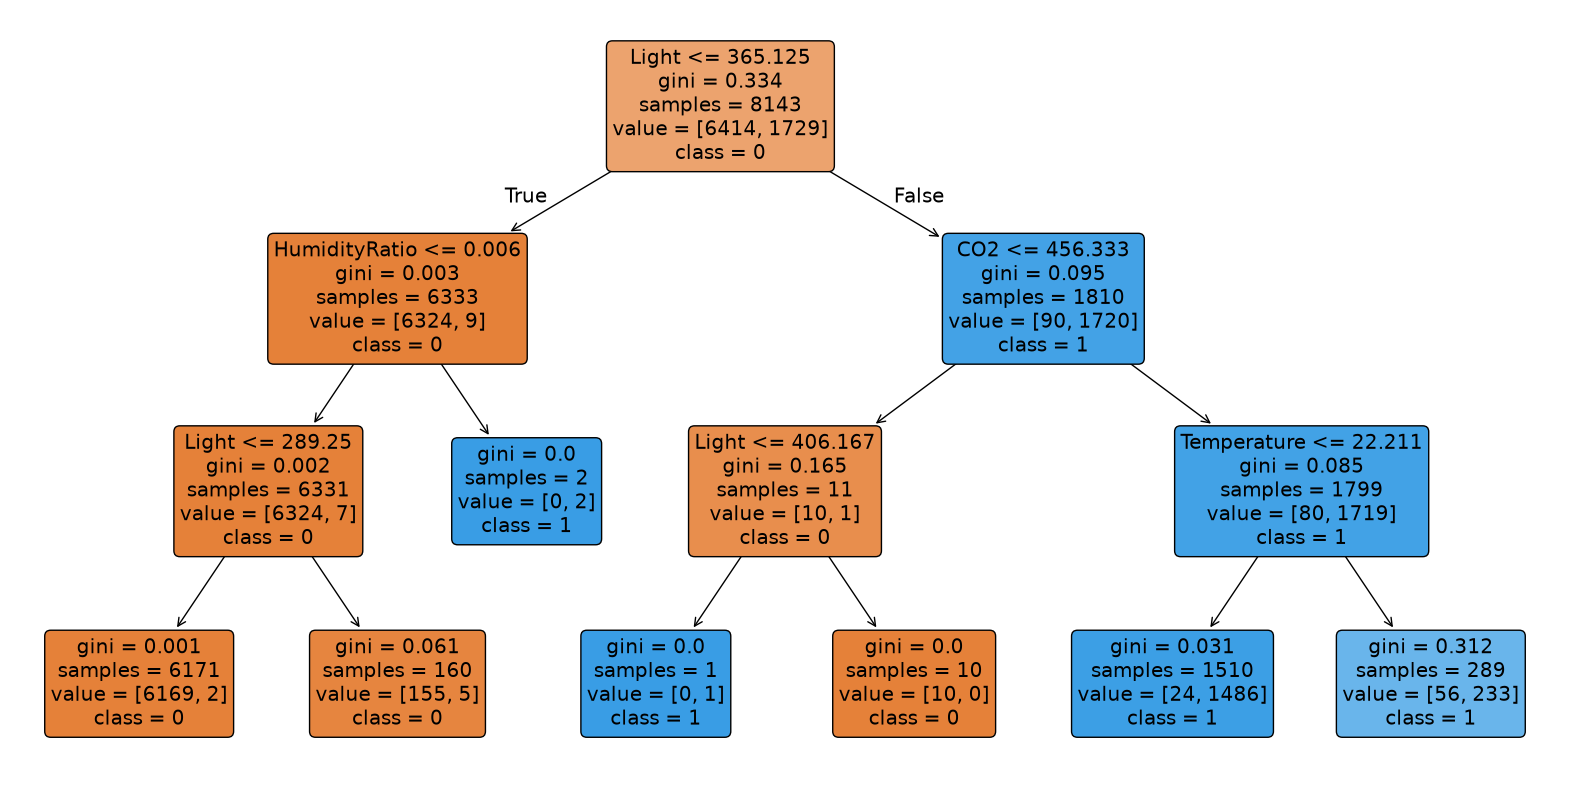

|--- Light <= 365.12
|   |--- HumidityRatio <= 0.01
|   |   |--- Light <= 289.25
|   |   |   |--- class: 0
|   |   |--- Light >  289.25
|   |   |   |--- class: 0
|   |--- HumidityRatio >  0.01
|   |   |--- class: 1
|--- Light >  365.12
|   |--- CO2 <= 456.33
|   |   |--- Light <= 406.17
|   |   |   |--- class: 1
|   |   |--- Light >  406.17
|   |   |   |--- class: 0
|   |--- CO2 >  456.33
|   |   |--- Temperature <= 22.21
|   |   |   |--- class: 1
|   |   |--- Temperature >  22.21
|   |   |   |--- class: 1



In [10]:
#(а)
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_tr, y_tr)

#(б)
y_tr_pred = tree.predict(X_tr)
y_va_pred = tree.predict(X_va)
print('Train accuracy:', accuracy_score(y_tr, y_tr_pred))
print('Validation accuracy:', accuracy_score(y_va, y_va_pred))

#(в)
plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=features, class_names=['0', '1'], filled=True, rounded=True)
plt.show()
print(export_text(tree, feature_names=features))

## Завдання 3. Випадковий ліс і порівняння

Decision Tree
Accuracy: 0.9782363977485928
Precision: 0.9724998510042315
Recall: 0.9817752960021779

Random Forest
Accuracy: 0.949343339587242
Precision: 0.9485097308963827
Recall: 0.9417281033740967



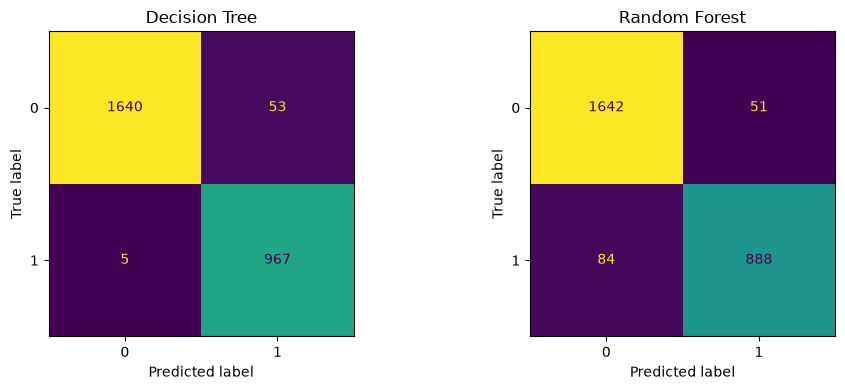

In [12]:
#(a)
forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(X_tr, y_tr)

#(б)
y_tree = tree.predict(X_va)
y_forest = forest.predict(X_va)
for name, pred in [('Decision Tree', y_tree), ('Random Forest', y_forest)]:
    print(name)
    print('Accuracy:', accuracy_score(y_va, pred))
    print('Precision:', precision_score(y_va, pred, average='macro'))
    print('Recall:', recall_score(y_va, pred, average='macro'))
    print()

#(в)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_va, y_tree, ax=axes[0], colorbar=False)
axes[0].set_title('Decision Tree')
ConfusionMatrixDisplay.from_predictions(y_va, y_forest, ax=axes[1], colorbar=False)
axes[1].set_title('Random Forest')
plt.tight_layout()
plt.show()

| Метрика | Decision Tree | Random Forest |
|---|---:|---:|
| Accuracy | 97,82% | 94,93% |
| Precision | 97,25% | 94,85% |
| Recall | 98,18% | 94,17% |

Кращою моделлю є Decision Tree, оскільки її точність становить 97,82%, що на 2,89 відсоткового пункта вище, ніж у Random Forest (94,93%). Дерево допустило 5 пропущених людей і 53 хибні тривоги, тоді як випадковий ліс — 84 пропущені людини та 51 хибну тривогу. Отже, дерево частіше дає хибні тривоги, а випадковий ліс — пропускає людей.

## Завдання 4. Експеримент з параметрами

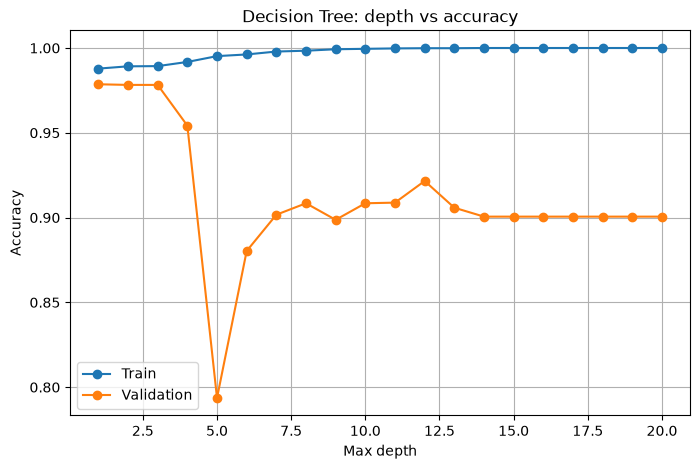

Best depth: 1
Best validation accuracy: 0.9786116322701689


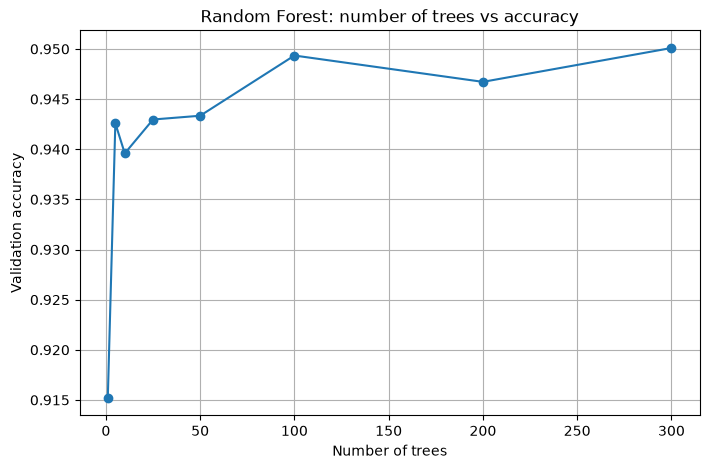

Best number of trees: 300
Best validation accuracy: 0.9500938086303939
Best tree test accuracy: 0.993129614438064
Best forest test accuracy: 0.9730311730926989


In [13]:
#(а)
depths = range(1, 21)
train_acc = []
val_acc = []
trees = {}
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=0)
    model.fit(X_tr, y_tr)
    trees[depth] = model
    train_acc.append(accuracy_score(y_tr, model.predict(X_tr)))
    val_acc.append(accuracy_score(y_va, model.predict(X_va)))
plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, marker='o', label='Train')
plt.plot(depths, val_acc, marker='o', label='Validation')
plt.xlabel('Max depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: depth vs accuracy')
plt.legend()
plt.grid()
plt.show()
best_depth = list(depths)[np.argmax(val_acc)]
print('Best depth:', best_depth)
print('Best validation accuracy:', max(val_acc))

#(б)
n_values = [1, 5, 10, 25, 50, 100, 200, 300]
forest_acc = []
forests = {}
for n in n_values:
    model = RandomForestClassifier(n_estimators=n, random_state=0)
    model.fit(X_tr, y_tr)
    forests[n] = model
    forest_acc.append(accuracy_score(y_va, model.predict(X_va)))
plt.figure(figsize=(8, 5))
plt.plot(n_values, forest_acc, marker='o')
plt.xlabel('Number of trees')
plt.ylabel('Validation accuracy')
plt.title('Random Forest: number of trees vs accuracy')
plt.grid()
plt.show()
best_n = n_values[np.argmax(forest_acc)]
print('Best number of trees:', best_n)
print('Best validation accuracy:', max(forest_acc))

#(в)
best_tree = trees[best_depth]
best_forest = forests[best_n]
tree_test_acc = accuracy_score(y_te, best_tree.predict(X_te))
forest_test_acc = accuracy_score(y_te, best_forest.predict(X_te))
print('Best tree test accuracy:', tree_test_acc)
print('Best forest test accuracy:', forest_test_acc)

## Завдання 5. Важливість ознак

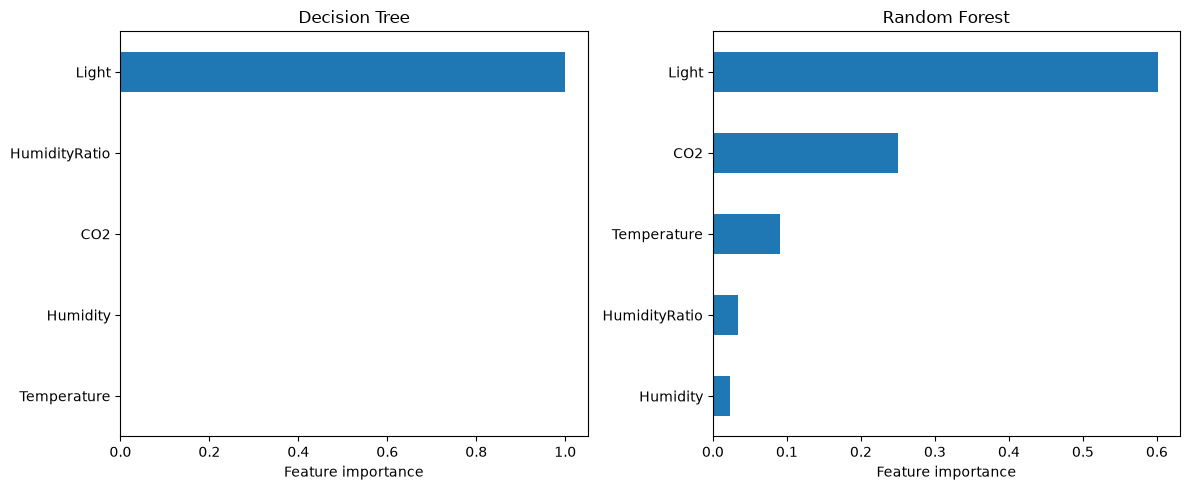

Топ-3 ознаки лісу:
Light          0.601124
CO2            0.250411
Temperature    0.090618
dtype: float64

Повний ліс
Validation accuracy: 0.9500938086303939
Test accuracy: 0.9730311730926989

Ліс без Light
Validation accuracy: 0.6848030018761726
Test accuracy: 0.3339827727645611



In [16]:
#(а)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in [(axes[0], best_tree, 'Decision Tree'), (axes[1], best_forest, 'Random Forest')]:
    importance = pd.Series(model.feature_importances_, index=features).sort_values()
    importance.plot(kind='barh', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Feature importance')
plt.tight_layout()
plt.show()

#(б)
print('Топ-3 ознаки лісу:')
print(pd.Series(best_forest.feature_importances_, index=features).sort_values(ascending=False).head(3))
print()

#(в)
features_reduced = [f for f in features if f != 'Light']
forest_reduced = RandomForestClassifier(n_estimators=100, random_state=0)
forest_reduced.fit(X_tr[features_reduced], y_tr)
for name, model, x_val, x_test in [
    ('Повний ліс', best_forest, X_va[features], X_te[features]),
    ('Ліс без Light', forest_reduced,
     X_va[features_reduced], X_te[features_reduced])
]:
    print(name)
    print('Validation accuracy:', accuracy_score(y_va, model.predict(x_val)))
    print('Test accuracy:', accuracy_score(y_te, model.predict(x_test)))
    print()

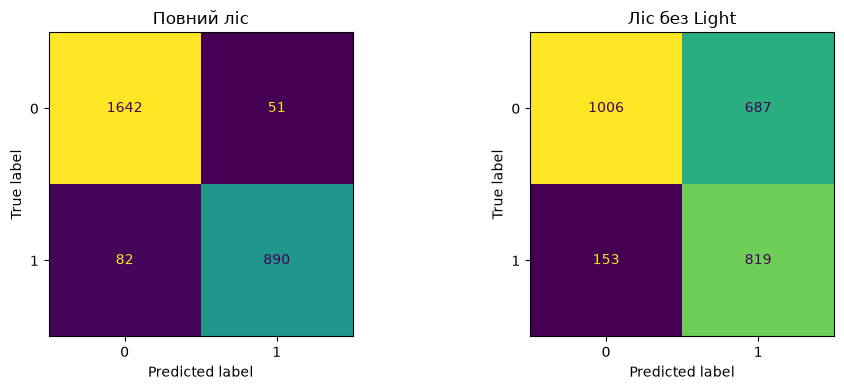

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, model, x_val, title in [
    (axes[0], best_forest, X_va[features], 'Повний ліс'),
    (axes[1], forest_reduced, X_va[features_reduced], 'Ліс без Light')
]:
    ConfusionMatrixDisplay.from_predictions(
        y_va, model.predict(x_val), ax=ax, colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

## Завдання 6. Нові випадки

In [21]:
#(а)
examples = pd.DataFrame([
    {'Temperature': 21.0, 'Humidity': 25.0, 'Light': 0,   'CO2': 400, 'HumidityRatio': 0.004},
    {'Temperature': 22.0, 'Humidity': 27.0, 'Light': 300, 'CO2': 600, 'HumidityRatio': 0.005},
    {'Temperature': 23.0, 'Humidity': 30.0, 'Light': 800, 'CO2': 900, 'HumidityRatio': 0.006},
    {'Temperature': 23.700, 'Humidity': 26.272, 'Light': 585.2, 'CO2': 749.2, 'HumidityRatio': 0.004764}
])[features]

#(б)
tree_pred = best_tree.predict(examples)
forest_pred = best_forest.predict(examples)

#(в)
forest_proba = best_forest.predict_proba(examples)
results = examples.copy()
results['Tree prediction'] = tree_pred
results['Forest prediction'] = forest_pred
results['Forest probabilities'] = [
    dict(zip(best_forest.classes_, p.round(3)))
    for p in forest_proba
]
display(results)

,Temperature,Humidity,Light,CO2,HumidityRatio,Tree prediction,Forest prediction,Forest probabilities
0,21.0,25.000,0.0,400.0,0.004000,0,0,"{0: 1.0, 1: 0.0}"
1,22.0,27.000,300.0,600.0,0.005000,0,0,"{0: 0.51, 1: 0.49}"
2,23.0,30.000,800.0,900.0,0.006000,1,1,"{0: 0.26, 1: 0.74}"
3,23.7,26.272,585.2,749.2,0.004764,1,0,"{0: 0.537, 1: 0.463}"


## Завдання 7. Порахувати руками

### (а) Індекс Джині кореня дерева та його дочірніх вузлів

Індекс Джині обчислюється за формулою:

`G = 1 - (p₀² + p₁²)`

де p₀ і p₁ — частки об'єктів відповідних класів у вузлі.

**1. Корінь дерева**

Кількість об'єктів: n = 8143.

Частки класів:

- p₀ = 6414 / 8143 ≈ 0.787670
- p₁ = 1729 / 8143 ≈ 0.212330

Індекс Джині:

`G = 1 - (0.787670² + 0.212330²)`

`G ≈ 1 - (0.620423 + 0.045084)`

`G ≈ 0.334491`

**2. Ліва дитина (вузол 1)**

Кількість об'єктів: n_L = 6333.

Частки класів:

- p₀ ≈ 0.998579
- p₁ ≈ 0.001421

Індекс Джині:

`G_L = 1 - (0.998579² + 0.001421²)`

`G_L ≈ 0.002838`

**3. Права дитина (вузол 6)**

Кількість об'єктів: n_R = 1810.

Частки класів:

- p₀ ≈ 0.049724
- p₁ ≈ 0.950276

Індекс Джині:

`G_R = 1 - (0.049724² + 0.950276²)`

`G_R ≈ 0.094503`

**4. Зважений індекс Джині після поділу**

Формула:

`G' = (n_L / n) * G_L + (n_R / n) * G_R`

Підставляємо значення:

`G' = (6333 / 8143) * 0.002838 + (1810 / 8143) * 0.094503`

`G' ≈ 0.023213`

Зменшення індексу Джині:

`ΔG = G - G'`

`ΔG = 0.334491 - 0.023213`

`ΔG ≈ 0.311278`

Отже, після поділу кореня індекс Джині зменшився на 0.311278, що свідчить про зменшення змішаності класів у дочірніх вузлах.

### (б) Влучність (Precision) і повнота (Recall) для класу 1

За результатами прогнозування Random Forest на валідаційній вибірці:

- Правильні прогнози класу 1: TP = 890.
- Усі прогнози класу 1: 941.
- Усі справжні об'єкти класу 1: 972.

**Влучність (Precision)** — частка правильних прогнозів серед усіх прогнозів класу 1.

`Precision = TP / кількість прогнозів класу 1`

`Precision = 890 / 941 ≈ 0.945802`

`Precision ≈ 94.58%`

**Повнота (Recall)** — частка правильно знайдених об'єктів серед усіх справжніх об'єктів класу 1.

`Recall = TP / кількість справжніх об'єктів класу 1`

`Recall = 890 / 972 ≈ 0.915638`

`Recall ≈ 91.56%`

Отже, влучність моделі становить приблизно 94.58%, а повнота — 91.56%.

### (в) Імовірність пропуску рядка у бутстреп-вибірці

Кількість навчальних рядків: n = 8143.

Формула:

`P = (1 - 1/n)^n`

Підставляємо значення:

`P = (1 - 1/8143)^8143`

`P = (8142/8143)^8143`

`P ≈ 0.367857`

У відсотках:

`P ≈ 0.367857 * 100% ≈ 36.79%`

Отже, приблизно 36.79% рядків початкової навчальної вибірки в середньому не потрапляють у бутстреп-вибірку одного дерева.

### Код обрахунку з величинами

In [18]:
# (а) Індекс Джині кореня та двох дітей
t = tree.tree_
for node in [0, t.children_left[0], t.children_right[0]]:
    counts = t.value[node][0]
    samples = t.n_node_samples[node]
    p = counts / counts.sum()
    gini = 1 - np.sum(p ** 2)
    print(f"\nВузол {node}")
    print("samples:", samples)
    print("value:", counts)
    print("Частки класів:", p)
    print("Gini:", gini)
root = 0
left = t.children_left[root]
right = t.children_right[root]
def gini(node):
    counts = t.value[node][0]
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)
n = t.n_node_samples[root]
n_left = t.n_node_samples[left]
n_right = t.n_node_samples[right]
weighted_gini = (n_left / n * gini(left) + n_right / n * gini(right))
print("\nЗважений Gini:", weighted_gini)
print("Зменшення Gini:", gini(root) - weighted_gini)

# (б) Precision і recall для класу 1
y_pred = best_forest.predict(X_va)
tp = np.sum((y_va == 1) & (y_pred == 1))
predicted_1 = np.sum(y_pred == 1)
actual_1 = np.sum(y_va == 1)
precision = tp / predicted_1
recall = tp / actual_1
print("Правильні прогнози класу 1:", tp)
print("Усього прогнозів класу 1:", predicted_1)
print("Справжніх об'єктів класу 1:", actual_1)
print("Precision:", precision)
print("Recall:", recall)

# (в) Імовірність не потрапити до вибірки дерева
n = len(X_tr)
p_out = (1 - 1 / n) ** n
print("\nКількість навчальних рядків:", n)
print("Імовірність не потрапити у вибірку дерева:", p_out)
print("У відсотках:", p_out * 100)


Вузол 0
samples: 8143
value: [0.78767039 0.21232961]
Частки класів: [0.78767039 0.21232961]
Gini: 0.3344914914236645

Вузол 1
samples: 6333
value: [0.99857887 0.00142113]
Частки класів: [0.99857887 0.00142113]
Gini: 0.002838215649186848

Вузол 6
samples: 1810
value: [0.04972376 0.95027624]
Частки класів: [0.04972376 0.95027624]
Gini: 0.09450260981044534

Зважений Gini: 0.023213084055410334
Зменшення Gini: 0.3112784073682542
Правильні прогнози класу 1: 890
Усього прогнозів класу 1: 941
Справжніх об'єктів класу 1: 972
Precision: 0.9458023379383634
Recall: 0.9156378600823045

Кількість навчальних рядків: 8143
Імовірність не потрапити у вибірку дерева: 0.36785685132330115
У відсотках: 36.785685132330116


## Висновки

1. **Завдання 1:** Класи в датасеті незбалансовані (клас 0 має 6414 записів, а клас 1 — 1729).
2. **Завдання 2:** Перше запитання дерева: `Light <= 365.125`. Одне з правил: якщо `Light <= 365.125` і `HumidityRatio <= 0.006`, то клас 0.
3. **Завдання 3:** Кращою моделлю на валідації виявилося Дерево рішень (точність 97.82% проти 94.93% у лісу). Дерево частіше дає хибні тривоги, а випадковий ліс — пропускає людей.
4. **Завдання 4:** Перенавчання дерева починається з глибини 4. Для випадкового лісу оптимально і достатньо 100 дерев.
5. **Завдання 5:** Найважливіші ознаки лісу: Light, CO2, Temperature. Видалення Light обвалило точність на тесті з ~0.97 до ~0.33 і різко збільшило кількість хибних тривог, оскільки ліс почав спиратися лише на інертні показники.
6. **Завдання 6:** Дерево і ліс можуть розходитися у прогнозах, оскільки дерево приймає рішення за одним набором правил, а ліс об'єднує та усереднює ймовірності багатьох дерев.
7. **Завдання 7:** Ручні розрахунки повністю збіглися з кодом. Після поділу кореня індекс Джині зменшився на 0.311. Влучність лісу для класу 1 становить 94.58%, повнота — 91.56%, а ймовірність пропуску рядка у бутстреп-вибірці — 36.79%.